# 03 · PPG time–frequency analysis

Raw PPG (photoplethysmography) from a Polar Verity Sense on the upper arm, 55 Hz, three green-light channels plus an ambient channel (`frame_type = ppg3_ambient1`). A spectrogram shows how the frequency content changes over time: the heartbeat appears as a bright band, its harmonic above it, and movement as broadband smears or its own lines (e.g. walking cadence). The Polar H10's ECG-derived heart rate is the reference.

1. preprocessing: uniform grid, band-pass, gaps
2. zoomable spectrogram with the ECG heart rate on top
3. heart rate from the spectral peak vs. ECG, at rest and during movement

**Zooming:** with ipympl installed every figure has a toolbar: the magnifier zooms into a box, the cross pans, the house resets. Long signals are drawn as min/max envelopes and refine down to the raw samples as you zoom; spectrograms are recomputed at a finer time resolution. Panels that share a time axis zoom together.

In [1]:
# Google Colab: fetch the repository (data + helpers) first. Elsewhere this cell does nothing.
import sys
if "google.colab" in sys.modules:
    !git clone -q --depth 1 https://github.com/Nsantis/sensorforge-examples /content/sensorforge-examples
    %cd /content/sensorforge-examples/notebooks
    !pip -q install ipympl
    from google.colab import output
    output.enable_custom_widget_manager()

In [2]:
from sfutils import *
setup_plots()   # zoomable figures with ipympl; static ones without it (or with SF_STATIC=1)

LOG = "../data/SF_20261031-105000_day-out-30min"
S = load_session(LOG)
print(S.manifest["startedAt"], "→", S.manifest["endedAt"], f"({S.end_s / 60:.0f} min, {S.tz})")
for (dev, sig), df in S.streams.items():
    if dev:
        print(f"  {S.name(dev):32s} {sig:5s} {len(df):>9,} rows")

2026-10-31T08:50:00.000Z → 2026-10-31T09:20:00.000Z (30 min, Europe/Helsinki)
  H10 971A3624 (chest)             hr        1,800 rows
  H10 971A3624 (chest)             rr        2,309 rows
  Sense 89672C22 (upper arm left)  ppg      98,639 rows
  Sense 89672C22 (upper arm left)  acc      95,725 rows
  Sense 89672C22 (upper arm left)  mag     182,545 rows
  Sense 89672C22 (upper arm left)  gyro     95,766 rows
  H10 971A3624 (chest)             acc     362,124 rows
  H10 971A3624 (chest)             ecg     234,403 rows
  Sense 89672C22 (upper arm left)  ppi       1,853 rows


## Preprocessing

`PPGGrid` (in `sfutils.py`):

1. signal = mean of `ch0…ch2` (larger values = more blood volume; see notebook 02)
2. split into continuous pieces at gaps in the sensor timestamps; each piece is interpolated onto a uniform grid at the measured rate and band-passed **0.8–5 Hz** (48–300 beats/min). The 0.8 Hz lower edge keeps breathing and slow movement out of the heart-rate band
3. `spectrogram()`: Hann windows; windows more than 10 % inside a gap are left blank; each time column is normalised to its own maximum so the heart-rate line stays visible even when movement changes the overall power

The ambient channel `ch3` measures light with the LEDs off; it is a useful check for light leaks but not subtracted here.

In [3]:
ppg = S.get("ppg")
grid = PPGGrid(S, ppg, channels=("ch0", "ch1", "ch2"), lo=0.8, hi=5.0)
print(f"measured rate {grid.fs:.3f} Hz, {grid.valid.mean():.1%} of the grid has data")

hr = S.get("hr", "H10")
hr_1s = hr[hr["hr_bpm"] > 0].groupby(np.floor(hr["elapsed_s"]))["hr_bpm"].mean()   # reference

measured rate 54.800 Hz, 100.0% of the grid has data


## Spectrogram

Top: the PPG spectrogram with the H10 heart rate (cyan). Bottom: arm movement. Zoom in to a few minutes and the spectrogram is recomputed with 8 s windows and a finer time step.

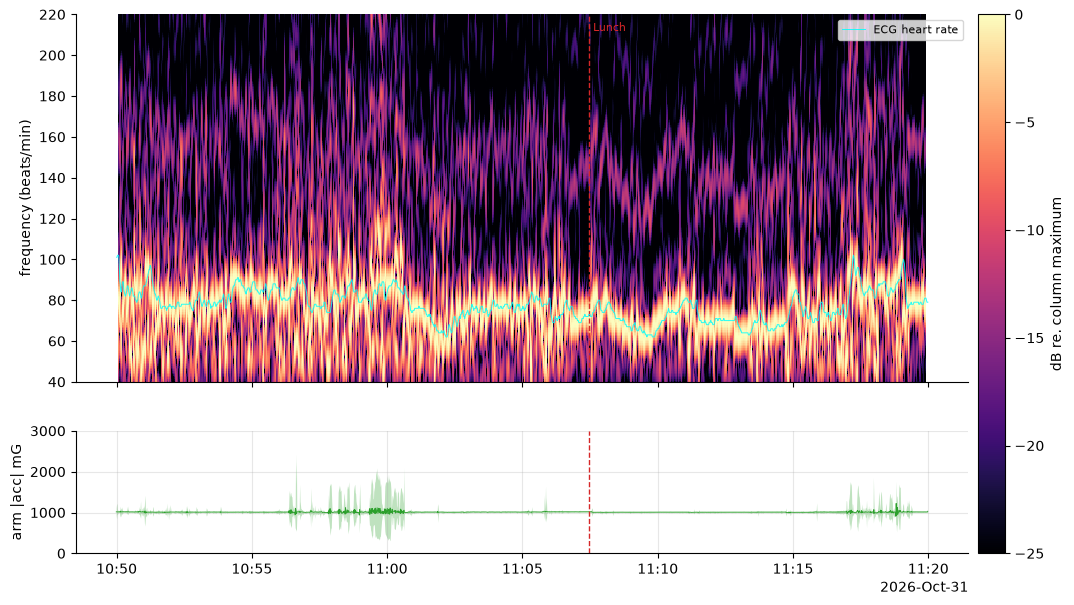

In [4]:
arm_acc = S.get("acc", S.device_of("ppg"))
arm_acc["mag"] = np.sqrt(arm_acc["x_mg"] ** 2 + arm_acc["y_mg"] ** 2 + arm_acc["z_mg"] ** 2.0)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
spec = ZoomSpectrogram(axes[0], grid, hr=hr_1s)
axes[0].set_ylim(40, 220)
fig.colorbar(spec.mesh, ax=axes, label="dB re. column maximum", pad=0.01, fraction=0.03)
plot_env(axes[1], S, arm_acc, "mag", "C2"); axes[1].set_ylabel("arm |acc| mG"); axes[1].set_ylim(0, 3000)
for ax in axes:
    decorate(ax, S, labels=ax is axes[0])
time_axis(axes[-1]); plt.show()

Without the overlay, and in a fixed window (`FROM`, `MINUTES`) at the fine resolution, for comparison:

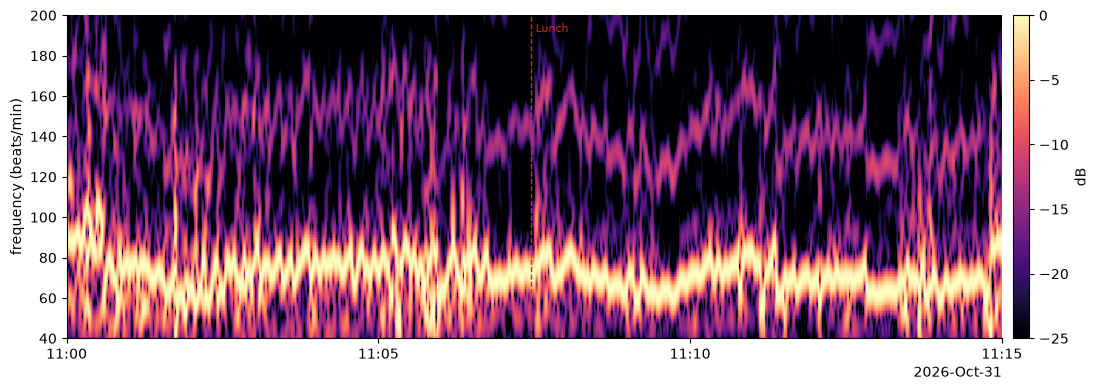

In [5]:
FROM, MINUTES = "11:00:00", 15
a = S.at(FROM)
fig, ax = plt.subplots(figsize=(12, 4))
spec_zoom = ZoomSpectrogram(ax, grid, a, a + MINUTES * 60)
ax.set_xlim(S.to_local(a), S.to_local(a + MINUTES * 60)); ax.set_ylim(40, 200)
decorate(ax, S, labels=True); time_axis(ax)
fig.colorbar(spec_zoom.mesh, ax=ax, label="dB", pad=0.01); plt.tight_layout(); plt.show()

## Heart rate from the spectral peak

The simplest PPG heart-rate estimator: the strongest frequency between 50 and 200 beats/min in each 16 s window, median-filtered over 5 windows. No motion compensation, so its error grows with movement; that is why the comparison is split by arm movement.

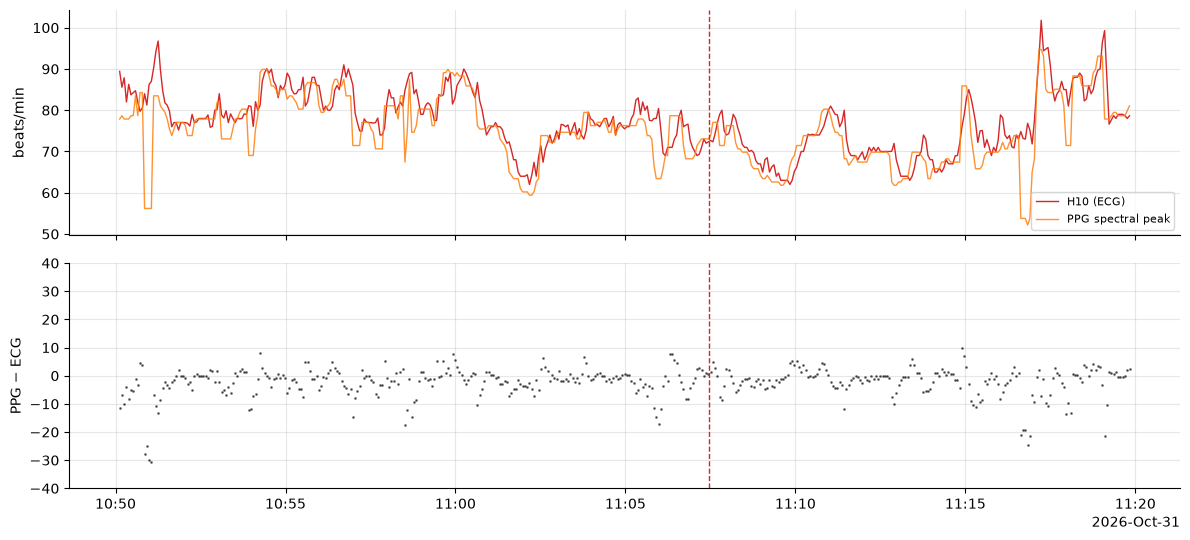

,windows,n,MAE beats/min,within ±5 beats/min %
0,all,447,3.7,77.2
1,arm still,382,3.5,78.3
2,arm moving,65,4.7,70.8


In [6]:
f, el, S_db = grid.spectrogram(win_s=16, step_s=4)
band = (f * 60 >= 50) & (f * 60 <= 200)
P = np.where(np.isnan(S_db[band]), -np.inf, S_db[band])
est = pd.Series(np.where(np.isfinite(P.max(axis=0)), f[band][P.argmax(axis=0)] * 60, np.nan), index=el)
est = est.rolling(5, center=True, min_periods=3).median()
ref = np.interp(el, hr_1s.index, hr_1s.to_numpy(), left=np.nan, right=np.nan)
mv = arm_acc.groupby(np.floor(arm_acc["elapsed_s"] / 4) * 4 + 2)["mag"].std()
moving = np.interp(el, mv.index, mv.to_numpy()) > 50     # mG
err = est.to_numpy() - ref

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(S.to_local(el), ref, color="C3", lw=1, label="H10 (ECG)")
axes[0].plot(S.to_local(el), est, color="C1", lw=1, alpha=0.85, label="PPG spectral peak")
axes[0].set_ylabel("beats/min"); axes[0].legend(fontsize=8)
axes[1].plot(S.to_local(el), err, ".", ms=2, color="k", alpha=0.5); axes[1].set_ylabel("PPG − ECG"); axes[1].set_ylim(-40, 40)
for ax in axes:
    decorate(ax, S)
time_axis(axes[-1]); plt.tight_layout(); plt.show()

ok = np.isfinite(err)
pd.DataFrame({"windows": ["all", "arm still", "arm moving"],
              "n": [ok.sum(), (ok & ~moving).sum(), (ok & moving).sum()],
              "MAE beats/min": [np.mean(np.abs(err[m])) for m in (ok, ok & ~moving, ok & moving)],
              "within ±5 beats/min %": [100 * np.mean(np.abs(err[m]) <= 5) for m in (ok, ok & ~moving, ok & moving)]}).round(1)

**Try next**

* single channels: `PPGGrid(S, ppg, channels=("ch1",))`; the channels see slightly different tissue
* the breathing band: `PPGGrid(S, ppg, lo=0.1, hi=0.6)` and a 60 s window shows respiration-induced modulation
* motion compensation: subtract the accelerometer spectrum (adaptive filtering, e.g. the TROIKA / JOSS family of methods)